# 4. Procedural CCLE proxy-normalized protein prediction partitions

This notebook keeps `utils_ccle.py` unchanged. The train-only same-gene proxy normalization/calibration helpers are defined directly in this notebook, then used for the proxy rows before the usual procedural Pearson, cosine, and MSE cascades.

The proxy prediction for each same-name gene/protein pair is:

```python
reg = LinearRegression()
reg.fit(x_train.reshape(-1, 1), y_train)
y_pred_test = reg.predict(x_test.reshape(-1, 1))
```

Only train samples are used to fit the proxy calibration, so the test set is not leaked into the calibration step.


In [1]:
from pathlib import Path
import hashlib
import json
import lzma
import pickle
import re
import warnings

import h5py
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------------
# Project paths
# ---------------------------------------------------------------------
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"

X_PATH = DATA_DIR / "transcriptomics_filtered.joblib"
Y_PATH = DATA_DIR / "proteomics_matched.joblib"
PEARSON_PATH = DATA_DIR / "full_pearson100.joblib"
SPEARMAN_PATH = DATA_DIR / "full_spearman100.joblib"

MODEL_DIRS = {
    "xgb": ROOT / "results_xgb",
    "xgb_zbig": ROOT / "res_xgb_zbig",
    "enet": ROOT / "results_enet",
    "enet_zbig": ROOT / "res_enet_zbig",
}

SCTRANSLATOR_BUNDLE_PATHS = {
    "2M": ROOT / "sc_predictions_2M.npz",
    "160K": ROOT / "sc_predictions_160K.npz",
    "10K": ROOT / "sc_predictions_10K.npz",
}

# ---------------------------------------------------------------------
# Analysis knobs
# ---------------------------------------------------------------------
RANDOM_SEED = 42
TEST_FRACTION = 0.20

# Main requested thresholds for higher-is-better metrics.
PEARSON_GOOD_THRESHOLDS = [0.30, 0.50, 0.70]
COSINE_GOOD_THRESHOLDS = [0.30, 0.50, 0.70]

# Main requested thresholds for MSE. Lower is better, so MSE is good when MSE <= threshold.
MSE_GOOD_THRESHOLDS = [0.30, 0.50, 0.70]

# Denser sweeps for sensitivity plots.
PEARSON_SWEEP_THRESHOLDS = [round(x, 2) for x in np.arange(0.10, 0.85, 0.05)]
COSINE_SWEEP_THRESHOLDS = [round(x, 2) for x in np.arange(0.10, 0.85, 0.05)]
MSE_SWEEP_THRESHOLDS = [round(x, 2) for x in np.arange(0.10, 1.05, 0.05)]

# Same-gene proxy full-correlation threshold sweep.
PROXY_CORR_THRESHOLDS = [round(x, 2) for x in np.arange(0.00, 0.85, 0.10)]

# Proxy-normalized notebook: same-gene proxy prediction is fitted as
# y_protein ~ RNA_gene on train samples only, using notebook-local
# sklearn.linear_model.LinearRegression helpers. utils_ccle.py is not modified.
SCALE_GENE_PROXY_WITH_TRAIN_LINEAR_MODEL = True

# Plotting controls.
FIGURE_DIR = ROOT / "procedural_proxy_norm_figures"
EXPORT_TABLE_DIR = ROOT / "procedural_proxy_norm_tables"
SAVE_OUTPUTS = False

FIGURE_DIR.mkdir(exist_ok=True)
EXPORT_TABLE_DIR.mkdir(exist_ok=True)

print("Root:", ROOT)
print("Data dir:", DATA_DIR)
print("Model folders:")
for name, folder in MODEL_DIRS.items():
    print(f"  {name:10s}: {folder}  exists={folder.exists()}")
print("\nscTranslator bundles:")
for name, path in SCTRANSLATOR_BUNDLE_PATHS.items():
    print(f"  {name:5s}: {path}  exists={path.exists()}")

Root: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison
Data dir: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\data
Model folders:
  xgb       : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\results_xgb  exists=True
  xgb_zbig  : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\res_xgb_zbig  exists=True
  enet      : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\results_enet  exists=True
  enet_zbig : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\res_enet_zbig  exists=True

scTranslator bundles:
  2M   : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\sc_predictions_2M.npz  exists=True
  160K : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\sc_predictions_160K.npz  exists=True
  10K  : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\sc_predictions_1

In [2]:
# Shared CCLE validation utilities
from pathlib import Path as _Path
import importlib.util as _importlib_util
import sys as _sys

# Make either a local utils_ccle.py or src/utils_ccle.py importable from repo root,
# notebooks/, notebooks2/, or this folder.
_utils_candidates = []
for _candidate in [
    _Path.cwd(),
    _Path.cwd().parent,
    _Path.cwd() / "notebooks",
    _Path.cwd().parent / "notebooks",
    _Path.cwd() / "notebooks2",
    _Path.cwd().parent / "notebooks2",
]:
    _utils_candidates.append(_candidate / "utils_ccle.py")
    _utils_candidates.append(_candidate / "src" / "utils_ccle.py")

_utils_path = next((p for p in _utils_candidates if p.exists()), None)
if _utils_path is None:
    raise FileNotFoundError(
        "Could not find utils_ccle.py. Place it next to this notebook or at src/utils_ccle.py."
    )

_spec = _importlib_util.spec_from_file_location("utils_ccle", _utils_path)
uc = _importlib_util.module_from_spec(_spec)
_sys.modules["utils_ccle"] = uc
_spec.loader.exec_module(uc)

for _name in getattr(uc, "__all__", []):
    globals()[_name] = getattr(uc, _name)

uc.set_module_globals(globals())
print("Loaded utilities:", uc.__file__)


Loaded utilities: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\src\utils_ccle.py


## Notebook-local proxy normalization helpers

The utility module is imported only for shared loading, plotting, and cascade helpers. The proxy calibration functions below intentionally override the imported proxy helpers inside the notebook namespace, without editing `utils_ccle.py`.


In [3]:
# Notebook-local proxy normalization/calibration functions.
# These override the imported names only inside this notebook session.
# The utils_ccle.py file is not edited.

from sklearn.linear_model import LinearRegression


def _notebook_index_by_protein(df):
    """Small local version used by notebook-local cascade helpers."""
    if df is None or len(df) == 0:
        return pd.DataFrame().rename_axis("protein")
    out = df.copy()
    out["protein"] = out["protein"].astype(str)
    return out.drop_duplicates("protein", keep="first").set_index("protein")


def _notebook_proxy_label(row):
    """Map proxy row metadata to the two displayed proxy stages."""
    proxy_type = str(row.get("proxy_type", "")).lower()
    run_label = str(row.get("run_label", "")).lower()
    if "spearman" in proxy_type or "spearman" in run_label:
        return "Proxy Spearman"
    return "Proxy Pearson"


def linear_scale_prediction(x_train, y_train, x_test):
    """
    Train-only same-gene proxy calibration.

    The fitted model is exactly the requested one:
        reg = LinearRegression()
        reg.fit(x_train.reshape(-1, 1), y_train)
        y_pred_test = reg.predict(x_test.reshape(-1, 1))

    Non-finite train pairs are removed before fitting. Non-finite test RNA
    values remain NaN in the returned prediction vector.
    """
    x_train = np.asarray(x_train, dtype=float).reshape(-1)
    y_train = np.asarray(y_train, dtype=float).reshape(-1)
    x_test = np.asarray(x_test, dtype=float).reshape(-1)

    train_mask = np.isfinite(x_train) & np.isfinite(y_train)
    if train_mask.sum() == 0:
        return np.full(x_test.shape, np.nan, dtype=float)

    # If only one train pair is available, LinearRegression can still fit an
    # intercept-only model. This keeps the fallback on the protein scale.
    reg = LinearRegression()
    reg.fit(x_train[train_mask].reshape(-1, 1), y_train[train_mask])

    y_pred = np.full(x_test.shape, np.nan, dtype=float)
    test_mask = np.isfinite(x_test)
    if test_mask.any():
        y_pred[test_mask] = reg.predict(x_test[test_mask].reshape(-1, 1))
    return y_pred


def build_same_gene_proxy_all_from_lookup(corr_lookup, proxy_type):
    """
    Build all same-name gene/protein proxy rows using notebook-local
    train-only LinearRegression calibration.

    The full-sample same-gene Pearson/Spearman lookup is kept only as metadata
    and for proxy-correlation eligibility analyses. It is not used to fit the
    test prediction calibration.
    """
    rows = []
    possible = sorted(set(Y.columns.astype(str)).intersection(set(X.columns.astype(str))))

    print(f"\nBuilding same-gene {proxy_type} proxy with notebook-local train LinearRegression")
    print("- Same-name protein/gene pairs possible:", len(possible))
    print("- Correlation lookup entries:", len(corr_lookup))
    print("- Test samples used:", len(test_samples))
    print("- Train samples used:", len(train_samples))

    for protein in possible:
        c = corr_lookup.get(protein, np.nan)
        if not np.isfinite(c):
            continue

        y_true = Y.loc[test_samples, protein].to_numpy(dtype=float)
        x_test = X.loc[test_samples, protein].to_numpy(dtype=float)

        if SCALE_GENE_PROXY_WITH_TRAIN_LINEAR_MODEL:
            x_train = X.loc[train_samples, protein].to_numpy(dtype=float)
            y_train = Y.loc[train_samples, protein].to_numpy(dtype=float)
            y_pred = linear_scale_prediction(x_train, y_train, x_test)
            variant = "train_linear_regression"
        else:
            y_pred = x_test
            variant = "raw_gene_value"

        metrics = compute_metrics(y_true, y_pred)

        rows.append({
            "protein": protein,
            "run_label": f"proxy_same_gene_{proxy_type}_train_linear",
            "model_family": "same_gene_proxy",
            "family_group": "proxy",
            "source_folder": f"proxy_same_gene_{proxy_type}",
            "normalization": variant,
            "h5_path": "",
            "proxy_type": proxy_type,
            "same_gene_corr_full": float(c),
            "test_mse": metrics["test_mse"],
            "test_pearson_corr": metrics["test_pearson_corr"],
            "test_cosine_similarity": metrics["test_cosine_similarity"],
            "n_test_used": metrics.get("n_test_used", np.nan),
            "selected_feature_count": 1,
            "train_n": len(train_samples),
            "test_n": len(test_samples),
            "split_hash": globals().get("model_split_hash", ""),
            "best_params": {
                "baseline": "same_name_gene_linear_regression_proxy",
                "proxy_type": proxy_type,
                "scaled": bool(SCALE_GENE_PROXY_WITH_TRAIN_LINEAR_MODEL),
                "calibration_model": "sklearn.linear_model.LinearRegression",
                "calibration_fit_samples": "train_only",
                "test_split_source": "read_from_xgb_enet_h5",
            },
        })

    return pd.DataFrame(rows)


def procedural_cosine_cascade(threshold, universe=None):
    """
    Procedural cascade for cosine similarity, matching the Pearson/MSE logic:
    proxy first, then ENet rescue, then XGB rescue, then remaining failures.
    """
    universe = pd.Index(protein_universe if universe is None else universe).astype(str)
    remaining = set(universe)
    rows = []

    proxy_idx = _notebook_index_by_protein(proxy_best_cosine)
    enet_idx = _notebook_index_by_protein(enet_best_cosine)
    xgb_idx = _notebook_index_by_protein(xgb_best_cosine)

    for protein in list(remaining):
        if protein in proxy_idx.index:
            row = proxy_idx.loc[protein]
            value = row.get("test_cosine_similarity", np.nan)
            if np.isfinite(value) and value >= threshold:
                rows.append({
                    "protein": protein,
                    "threshold": threshold,
                    "stage": _notebook_proxy_label(row),
                    "metric": value,
                    "run_label": row.get("run_label", ""),
                })
                remaining.remove(protein)

    for protein in list(remaining):
        if protein in enet_idx.index:
            row = enet_idx.loc[protein]
            value = row.get("test_cosine_similarity", np.nan)
            if np.isfinite(value) and value >= threshold:
                rows.append({
                    "protein": protein,
                    "threshold": threshold,
                    "stage": "ENet",
                    "metric": value,
                    "run_label": row.get("run_label", ""),
                })
                remaining.remove(protein)

    for protein in list(remaining):
        if protein in xgb_idx.index:
            row = xgb_idx.loc[protein]
            value = row.get("test_cosine_similarity", np.nan)
            if np.isfinite(value) and value >= threshold:
                rows.append({
                    "protein": protein,
                    "threshold": threshold,
                    "stage": "XGB",
                    "metric": value,
                    "run_label": row.get("run_label", ""),
                })
                remaining.remove(protein)

    for protein in sorted(remaining):
        rows.append({
            "protein": protein,
            "threshold": threshold,
            "stage": "Still not good",
            "metric": np.nan,
            "run_label": "",
        })

    return pd.DataFrame(rows)


# Synchronize the notebook-local overrides into the utility module's runtime
# globals only, so utility functions that rely on globals can see them during
# this notebook execution. This does not write to utils_ccle.py.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

print("Notebook-local proxy helpers active:")
print("- linear_scale_prediction -> sklearn.linear_model.LinearRegression")
print("- build_same_gene_proxy_all_from_lookup -> notebook-local override")
print("- procedural_cosine_cascade -> notebook-local helper")


Notebook-local proxy helpers active:
- linear_scale_prediction -> sklearn.linear_model.LinearRegression
- build_same_gene_proxy_all_from_lookup -> notebook-local override
- procedural_cosine_cascade -> notebook-local helper


## 1. Load transcriptomics, proteomics, and correlation matrices

The proteomics table is oriented as samples × proteins. If the loaded object is proteins × samples, it is transposed automatically.

In [4]:
for p in [X_PATH, Y_PATH, PEARSON_PATH, SPEARMAN_PATH]:
    require_file(p)

X_raw = joblib.load(X_PATH)
Y_raw = joblib.load(Y_PATH)
pearson_corr_obj = joblib.load(PEARSON_PATH)
spearman_corr_obj = joblib.load(SPEARMAN_PATH)

X = X_raw.copy()
Y0 = Y_raw.copy()

X.index = X.index.map(str)
X.columns = X.columns.map(str)
Y0.index = Y0.index.map(str)
Y0.columns = Y0.columns.map(str)

# Detect proteomics orientation and convert to rows=samples, columns=proteins.
x_samples = set(X.index)
y_index_overlap = len(x_samples & set(Y0.index))
y_column_overlap = len(x_samples & set(Y0.columns))

if y_index_overlap >= y_column_overlap:
    Y = Y0.copy()
    proteomics_orientation = "samples_as_rows__proteins_as_columns"
else:
    Y = Y0.T.copy()
    proteomics_orientation = "proteins_as_rows__samples_as_columns__transposed"

Y.index = Y.index.map(str)
Y.columns = Y.columns.map(str)

common_samples = X.index.intersection(Y.index)
X = X.loc[common_samples].copy()
Y = Y.loc[common_samples].copy()

# scTranslator predictions are compared to this ground-truth table.
# If the project already defines GT_scaled upstream, this notebook uses Y as the default equivalent.
GT_scaled = Y.copy()

protein_universe = pd.Index(Y.columns.astype(str)).unique()

print("Loaded data")
print("- Transcriptomics shape:", X.shape, "(samples x genes)")
print("- Proteomics shape:     ", Y.shape, "(samples x proteins)")
print("- Proteomics orientation:", proteomics_orientation)
print("- Common samples:", len(common_samples))
print("- Proteins in universe:", len(protein_universe))
print("- First samples:", list(common_samples[:5]))
print("- First genes:", list(X.columns[:5]))
print("- First proteins:", list(Y.columns[:5]))

print("\nCorrelation objects:")
print("- Pearson type:", type(pearson_corr_obj), "shape:", getattr(pearson_corr_obj, "shape", None))
print("- Spearman type:", type(spearman_corr_obj), "shape:", getattr(spearman_corr_obj, "shape", None))

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

Loaded data
- Transcriptomics shape: (369, 22614) (samples x genes)
- Proteomics shape:      (369, 5113) (samples x proteins)
- Proteomics orientation: samples_as_rows__proteins_as_columns
- Common samples: 369
- Proteins in universe: 5113
- First samples: ['MDAMB468_BREAST', 'SH4_SKIN', 'AU565_BREAST', 'KMRC1_KIDNEY', 'CAL51_BREAST']
- First genes: ['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2ML1']
- First proteins: ['A2M', 'AAAS', 'AACS', 'AAGAB', 'AAK1']

Correlation objects:
- Pearson type: <class 'pandas.core.frame.DataFrame'> shape: (5113, 51989)
- Spearman type: <class 'pandas.core.frame.DataFrame'> shape: (5113, 51989)


## 2. Helper functions

These functions load saved `.h5` results, recover the exact test split, compute metrics, and build same-gene proxy predictions without imposing a fixed proxy-correlation threshold.

## 3. Load saved ENet/XGB result summaries

Only metrics and metadata are loaded from `.h5` files. Models are not retrained.

In [5]:
model_rows = []
folder_counts = {}

for label, folder in MODEL_DIRS.items():
    folder = Path(folder)
    files = sorted(folder.glob("*.h5")) if folder.exists() else []
    folder_counts[label] = len(files)

    for path in files:
        row = load_h5_summary(path, label)
        if "h5_path" not in row:
            row["h5_path"] = str(path)
        model_rows.append(row)

model_results = pd.DataFrame(model_rows)

if len(model_results):
    for c in [
        "test_mse",
        "test_pearson_corr",
        "test_cosine_similarity",
        "selected_feature_count",
        "train_n",
        "test_n",
        "select_k",
        "file_size_mb",
    ]:
        if c in model_results.columns:
            model_results[c] = pd.to_numeric(model_results[c], errors="coerce")

    model_results = add_family_group(model_results)

print("Saved model file counts")
for label, n in folder_counts.items():
    print(f"- {label:12s}: {n:6d} H5 files")

print("\nSaved model result table")
print("- Saved model rows:", len(model_results))
print("- Unique proteins: ", model_results["protein"].nunique() if len(model_results) and "protein" in model_results.columns else 0)

if len(model_results) and "load_error" in model_results.columns:
    n_errors = int(model_results["load_error"].notna().sum())
    print("- H5 load errors:  ", n_errors)
    if n_errors:
        display(model_results.loc[model_results["load_error"].notna(), ["h5_path", "load_error"]].head(10))

if len(model_results):
    display(
        model_results.groupby(["family_group", "run_label"])["protein"]
        .nunique()
        .sort_values(ascending=False)
        .to_frame("proteins")
    )
    display(model_results.head())
else:
    raise RuntimeError("No saved ENet/XGB .h5 result files were found in MODEL_DIRS.")

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

Saved model file counts
- xgb         :  20462 H5 files
- xgb_zbig    :   5113 H5 files
- enet        :  20602 H5 files
- enet_zbig   :   5113 H5 files

Saved model result table
- Saved model rows: 51290
- Unique proteins:  5113
- H5 load errors:   0


proteins
family_group run_label                                    
enet         enet | none | fast | k2000               5113
             enet | ranking | fast | k2000            5113
             enet | unknown | fast | k2000            5113
             enet | zscore | fast | k2000             5113
             enet_zbig | zscore | fast | k5000        5113
xgb          xgb | none | fast | k2000                5113
             xgb | qbin50 | fast | k2000              5113
             xgb | rank | fast | k2000                5113
             xgb | zscore | fast | k2000              5113
             xgb_zbig | zscore | current | k5000      5113
enet         enet | none | fast | k500                  50
             enet | unknown | fast | k500               50
             enet | zscore | fast | k500                50
xgb          xgb | none | tiny | k50                     5
             xgb | qbin50 | tiny | k50                   5

,protein,run_label,model_family,source_folder,normalization,grid_preset,select_k,h5_path,file,file_size_mb,test_mse,test_pearson_corr,test_cosine_similarity,selected_feature_count,train_n,test_n,best_params,load_error,family_group
0,A2M,xgb | none | fast | k2000,xgb,xgb,none,fast,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_none_fast_k2000.h5,0.120128,0.760331,0.469012,0.554128,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None,xgb
1,A2M,xgb | none | tiny | k50,xgb,xgb,none,tiny,50,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_none_tiny_k50.h5,0.083029,0.753375,0.477427,0.558124,50,295,74,"{'colsample_bytree': 0.8, 'device': 'cpu', 'ga...",None,xgb
2,A2M,xgb | qbin50 | fast | k2000,xgb,xgb,qbin50,fast,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_qbin50_fast_k2000.h5,2.574004,0.751074,0.466232,0.560768,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None,xgb
3,A2M,xgb | qbin50 | tiny | k50,xgb,xgb,qbin50,tiny,50,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_qbin50_tiny_k50.h5,2.617776,0.778497,0.451791,0.539072,50,295,74,"{'colsample_bytree': 0.8, 'device': 'cpu', 'ga...",None,xgb
4,A2M,xgb | rank | fast | k2000,xgb,xgb,rank,fast,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_rank_fast_k2000.h5,7.608312,0.760331,0.469012,0.554128,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None,xgb


## 4. Recover the exact H5 test split

The proxy models and scTranslator predictions are evaluated on the same test samples used by the saved ENet/XGB `.h5` files.

In [6]:
if "h5_path" not in model_results.columns:
    raise RuntimeError("model_results has no h5_path column, so the H5 test split cannot be read.")

split_rows = []
split_samples_by_hash = {}

h5_paths = (
    model_results["h5_path"]
    .dropna()
    .astype(str)
    .loc[lambda s: s.str.len() > 0]
    .unique()
)

for path in h5_paths:
    try:
        h5_test_samples = read_test_samples_from_h5(path)
        if h5_test_samples is None:
            split_rows.append({"h5_path": path, "readable": False, "test_n": np.nan, "split_hash": None})
            continue

        h5_test_samples = pd.Index(h5_test_samples.astype(str))
        h = split_hash(h5_test_samples)
        split_samples_by_hash[h] = h5_test_samples
        split_rows.append({"h5_path": path, "readable": True, "test_n": len(h5_test_samples), "split_hash": h})

    except Exception as e:
        split_rows.append({
            "h5_path": path,
            "readable": False,
            "test_n": np.nan,
            "split_hash": None,
            "error": f"{type(e).__name__}: {e}",
        })

h5_split_check = pd.DataFrame(split_rows)

print("H5 test split readability")
display(
    h5_split_check
    .groupby(["readable", "split_hash"], dropna=False)
    .agg(files=("h5_path", "count"), test_n=("test_n", "median"))
    .reset_index()
    .sort_values(["readable", "files"], ascending=[False, False])
)

readable = h5_split_check[h5_split_check["readable"]].copy()
if readable.empty:
    raise RuntimeError(
        "Could not read test_samples from any H5 file. "
        "The saved XGB/ENet files probably do not store the test split."
    )

unique_hashes = readable["split_hash"].dropna().unique()
if len(unique_hashes) != 1:
    display(
        readable
        .groupby("split_hash")
        .agg(files=("h5_path", "count"), test_n=("test_n", "median"))
        .sort_values("files", ascending=False)
    )
    raise RuntimeError(
        f"Found {len(unique_hashes)} different H5 test splits. "
        "A single proxy/scTranslator split cannot fairly match all models."
    )

model_split_hash = unique_hashes[0]
model_test_samples = pd.Index(split_samples_by_hash[model_split_hash].astype(str))
common_samples_index = pd.Index(np.asarray(common_samples, dtype=str))

test_samples = model_test_samples.intersection(common_samples_index)
train_samples = pd.Index([s for s in common_samples_index if s not in set(test_samples)])

print("\nUsing exact XGB/ENet H5 test split")
print("- Split hash:", model_split_hash)
print("- Test samples:", len(test_samples))
print("- Train samples:", len(train_samples))
print("- Test fraction:", len(test_samples) / len(common_samples_index))
print("- First test samples:", list(test_samples[:5]))

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

H5 test split readability


,readable,split_hash,files,test_n
0,True,d0750f1c44a2,51290,74.0



Using exact XGB/ENet H5 test split
- Split hash: d0750f1c44a2
- Test samples: 74
- Train samples: 295
- Test fraction: 0.2005420054200542
- First test samples: ['HDMYZ_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'JHH5_LIVER', 'CAOV3_OVARY', 'K562_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'NCIH1693_LUNG']


## 5. Build train-normalized same-gene Pearson and Spearman proxy models

This section builds **all available same-gene proxy predictions first** and stores the full same-gene correlation as metadata. Thresholds are applied later during plotting.

Unlike the raw-proxy version, each proxy prediction is calibrated on training samples only:

```python
reg = LinearRegression()
reg.fit(x_train.reshape(-1, 1), y_train)
y_pred_test = reg.predict(x_test.reshape(-1, 1))
```

This means the proxy still uses exactly one RNA feature, but its scale and intercept are learned from the training protein values before evaluating on the test samples.


In [7]:
possible_same_name = sorted(set(Y.columns.astype(str)).intersection(set(X.columns.astype(str))))

print("Proxy calibration enabled:", SCALE_GENE_PROXY_WITH_TRAIN_LINEAR_MODEL)
print("Calibration model: sklearn.linear_model.LinearRegression, fit on train samples only")

print("Precomputing same-name Pearson lookup...")
pearson_lookup = build_same_name_corr_lookup_fast(pearson_corr_obj, possible_same_name)

print("Precomputing same-name Spearman lookup...")
spearman_lookup = build_same_name_corr_lookup_fast(spearman_corr_obj, possible_same_name)

pearson_proxy = build_same_gene_proxy_all_from_lookup(pearson_lookup, proxy_type="pearson")
spearman_proxy = build_same_gene_proxy_all_from_lookup(spearman_lookup, proxy_type="spearman")

proxy_results = pd.concat([pearson_proxy, spearman_proxy], ignore_index=True, sort=False)
proxy_results = add_family_group(proxy_results)

all_results = pd.concat([model_results, proxy_results], ignore_index=True, sort=False)
all_results = add_family_group(all_results)

print("\nProxy rows built without proxy-correlation filtering")
print("- Pearson proxy rows: ", len(pearson_proxy))
print("- Spearman proxy rows:", len(spearman_proxy))
print("- Total proxy rows:   ", len(proxy_results))
print("- Proxy normalization variants:", sorted(proxy_results["normalization"].dropna().astype(str).unique()))
print("\nCombined result table")
print("- Saved model rows:", len(model_results))
print("- Proxy rows:      ", len(proxy_results))
print("- Total rows:      ", len(all_results))
print("- Unique proteins: ", all_results["protein"].nunique())

display(
    all_results.groupby(["family_group", "run_label"])["protein"]
    .nunique()
    .sort_values(ascending=False)
    .to_frame("proteins")
)

display(
    all_results.groupby("family_group")
    .agg(
        rows=("protein", "count"),
        proteins=("protein", "nunique"),
        pearson_nonmissing=("test_pearson_corr", lambda s: s.notna().sum()),
        mse_nonmissing=("test_mse", lambda s: s.notna().sum()),
    )
)

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

Proxy calibration enabled: True
Calibration model: sklearn.linear_model.LinearRegression, fit on train samples only
Precomputing same-name Pearson lookup...
Precomputing same-name Spearman lookup...

Building same-gene pearson proxy with notebook-local train LinearRegression
- Same-name protein/gene pairs possible: 4843
- Correlation lookup entries: 4843
- Test samples used: 74
- Train samples used: 295

Building same-gene spearman proxy with notebook-local train LinearRegression
- Same-name protein/gene pairs possible: 4843
- Correlation lookup entries: 4843
- Test samples used: 74
- Train samples used: 295

Proxy rows built without proxy-correlation filtering
- Pearson proxy rows:  4843
- Spearman proxy rows: 4843
- Total proxy rows:    9686
- Proxy normalization variants: ['train_linear_regression']

Combined result table
- Saved model rows: 51290
- Proxy rows:       9686
- Total rows:       60976
- Unique proteins:  5113


proteins
family_group run_label                                      
enet         enet | none | fast | k2000                 5113
             enet_zbig | zscore | fast | k5000          5113
xgb          xgb | zscore | fast | k2000                5113
             xgb | rank | fast | k2000                  5113
             xgb | qbin50 | fast | k2000                5113
             xgb | none | fast | k2000                  5113
             xgb_zbig | zscore | current | k5000        5113
enet         enet | zscore | fast | k2000               5113
             enet | unknown | fast | k2000              5113
             enet | ranking | fast | k2000              5113
proxy        proxy_same_gene_spearman_train_linear      4843
             proxy_same_gene_pearson_train_linear       4843
enet         enet | zscore | fast | k500                  50
             enet | none | fast | k500                    50
             enet | unknown | fast | k500                 50
xgb          xgb | none | tiny | k50                       5
             xgb | qbin50 | tiny | k50                     5

,rows,proteins,pearson_nonmissing,mse_nonmissing
family_group,,,,
enet,25715,5113,24642,25715
proxy,9686,4843,9686,9686
xgb,25575,5113,25575,25575


## 6. Best-per-family tables

For the procedural cascade, each family contributes its best result per protein:

- Proxy: best of the train-normalized same-gene Pearson and same-gene Spearman proxy.
- ENet: best ENet result per protein.
- XGB: best XGB result per protein.

For Pearson and cosine similarity, higher is better. For MSE, lower is better.


In [8]:
best_tables = {
    "pearson": {
        "proxy": best_family("test_pearson_corr", "proxy", higher=True),
        "enet": best_family("test_pearson_corr", "enet", higher=True),
        "xgb": best_family("test_pearson_corr", "xgb", higher=True),
    },
    "cosine": {
        "proxy": best_family("test_cosine_similarity", "proxy", higher=True),
        "enet": best_family("test_cosine_similarity", "enet", higher=True),
        "xgb": best_family("test_cosine_similarity", "xgb", higher=True),
    },
    "mse": {
        "proxy": best_family("test_mse", "proxy", higher=False),
        "enet": best_family("test_mse", "enet", higher=False),
        "xgb": best_family("test_mse", "xgb", higher=False),
    },
}

for metric_name, fams in best_tables.items():
    print(f"\nBest tables by {metric_name}")
    for fam, df in fams.items():
        print(f"- {fam:6s}: {len(df):6d} proteins")

# Helpful aliases.
proxy_best_pearson = best_tables["pearson"]["proxy"]
enet_best_pearson = best_tables["pearson"]["enet"]
xgb_best_pearson = best_tables["pearson"]["xgb"]

proxy_best_cosine = best_tables["cosine"]["proxy"]
enet_best_cosine = best_tables["cosine"]["enet"]
xgb_best_cosine = best_tables["cosine"]["xgb"]

proxy_best_mse = best_tables["mse"]["proxy"]
enet_best_mse = best_tables["mse"]["enet"]
xgb_best_mse = best_tables["mse"]["xgb"]

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass



Best tables by pearson
- proxy :   4843 proteins
- enet  :   5102 proteins
- xgb   :   5113 proteins

Best tables by cosine
- proxy :   4843 proteins
- enet  :   5113 proteins
- xgb   :   5113 proteins

Best tables by mse
- proxy :   4843 proteins
- enet  :   5113 proteins
- xgb   :   5113 proteins


## 7. Plotting and procedural partition helpers

In [9]:
CASCADE_ORDER_BASE = [
    "Proxy Pearson",
    "Proxy Spearman",
    "ENet",
    "XGB",
    "Still not good",
]

CASCADE_ORDER_WITH_SC = [
    "Proxy Pearson",
    "Proxy Spearman",
    "ENet",
    "XGB",
    "scTranslator 2M",
    "scTranslator 160K",
    "scTranslator 10K",
    "Still not good after scTranslator",
]

MSE_WINNER_ORDER = [
    "Proxy Pearson lowest MSE",
    "Proxy Spearman lowest MSE",
    "ENet lowest MSE",
    "XGB lowest MSE",
    "No valid MSE",
]

COLOR_MAP = {
    "Proxy Pearson": "#4C78A8",
    "Proxy Spearman": "#72B7B2",
    "ENet": "#54A24B",
    "XGB": "#F58518",
    "scTranslator 2M": "#B279A2",
    "scTranslator 160K": "#9D755D",
    "scTranslator 10K": "#BAB0AC",
    "Still not good": "#E45756",
    "Still not good after scTranslator": "#E45756",
    "Proxy Pearson lowest MSE": "#4C78A8",
    "Proxy Spearman lowest MSE": "#72B7B2",
    "ENet lowest MSE": "#54A24B",
    "XGB lowest MSE": "#F58518",
    "No valid MSE": "#E45756",
    "Proxy retained / no lower MSE found": "#4C78A8",
    "ENet improves over proxy": "#54A24B",
    "XGB improves over previous best": "#F58518",
    "ENet first valid MSE": "#8CD17D",
    "XGB first valid MSE": "#FFBE7D",
    "No valid comparison": "#E45756",
    "Eligible and good": "#4C78A8",
    "Eligible but not good": "#F58518",
    "No eligible proxy": "#E45756",
}

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

## 8. Main procedural Pearson analyses: 0.30, 0.50, 0.70

Each protein is assigned to the first successful stage:

```text
Proxy Pearson/Spearman → ENet → XGB → Still not good
```

Procedural Pearson cascade summary


stage,Proxy Pearson,Proxy Spearman,ENet,XGB,Still not good
threshold,,,,,
0.3,1815,1837,1238,49,174
0.5,1147,1140,1265,116,1445
0.7,448,472,486,37,3670


,threshold,stage,proteins,total_proteins,percent
0,0.3,Proxy Pearson,1815,5113,35.497751
1,0.3,Proxy Spearman,1837,5113,35.928027
2,0.3,ENet,1238,5113,24.212791
3,0.3,XGB,49,5113,0.958341
4,0.3,Still not good,174,5113,3.403090
5,0.5,Proxy Pearson,1147,5113,22.433014
6,0.5,Proxy Spearman,1140,5113,22.296108
7,0.5,ENet,1265,5113,24.740857
8,0.5,XGB,116,5113,2.268727
9,0.5,Still not good,1445,5113,28.261295


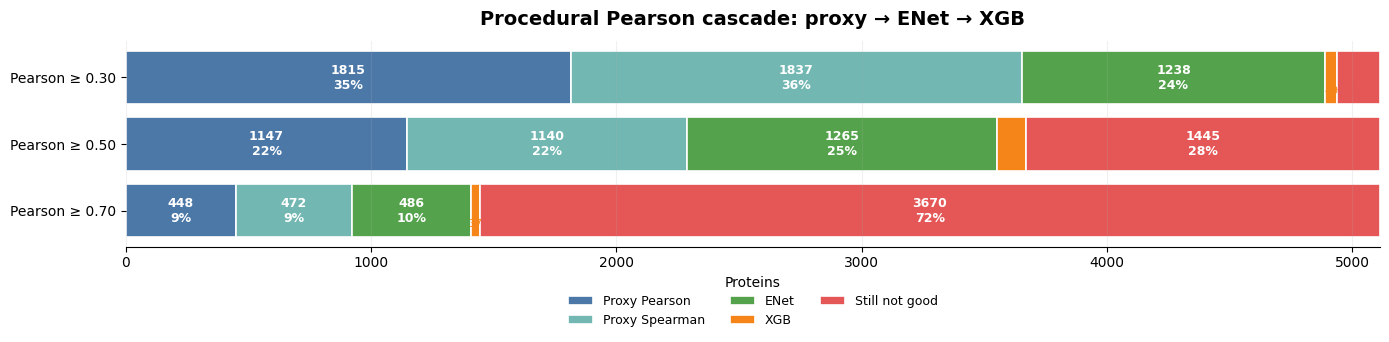

In [10]:
main_assignments = pd.concat(
    [procedural_pearson_cascade(thr, include_sc=False) for thr in PEARSON_GOOD_THRESHOLDS],
    ignore_index=True,
)

main_summary = summarize_assignments(main_assignments, order=CASCADE_ORDER_BASE)

print("Procedural Pearson cascade summary")
display(
    main_summary
    .pivot_table(index="threshold", columns="stage", values="proteins", fill_value=0, aggfunc="sum")
    .reindex(columns=CASCADE_ORDER_BASE)
)

display(main_summary)

plot_stacked_partition_rows(
    main_summary,
    title="Procedural Pearson cascade: proxy → ENet → XGB",
    order=CASCADE_ORDER_BASE,
    save_name="pearson_cascade_030_050_070.png",
)

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

## 9. Pearson threshold sweep

This is the same procedural cascade, but for many Pearson-good thresholds. It shows how sensitive the conclusion is to the chosen definition of “predicted well.”

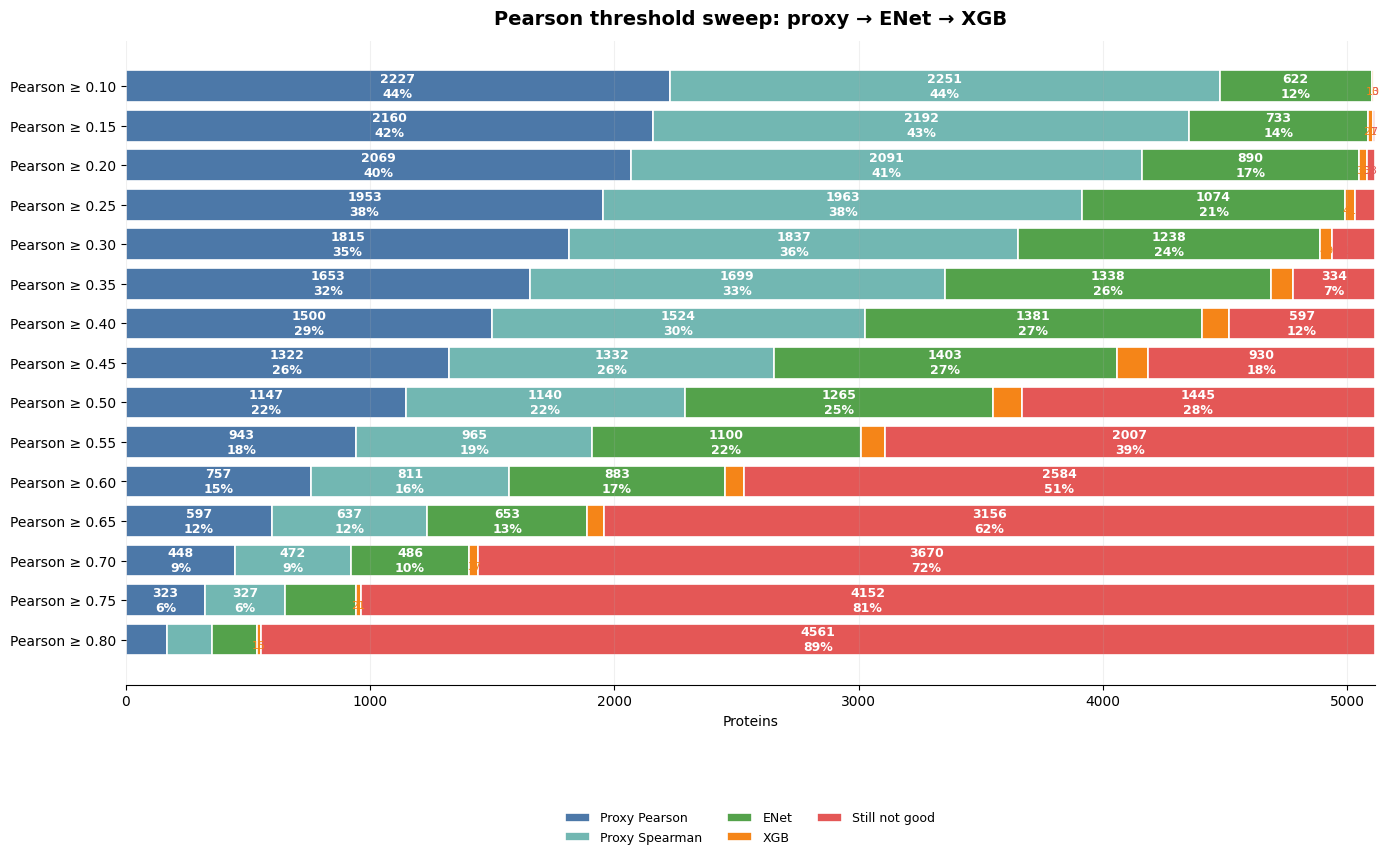

In [11]:
sweep_assignments = pd.concat(
    [procedural_pearson_cascade(thr, include_sc=False) for thr in PEARSON_SWEEP_THRESHOLDS],
    ignore_index=True,
)

sweep_summary = summarize_assignments(sweep_assignments, order=CASCADE_ORDER_BASE)

plot_stacked_partition_rows(
    sweep_summary,
    title="Pearson threshold sweep: proxy → ENet → XGB",
    order=CASCADE_ORDER_BASE,
    save_name="pearson_threshold_sweep.png",
    figsize=(14, max(5, 0.45 * len(PEARSON_SWEEP_THRESHOLDS) + 2.0)),
)

if SAVE_OUTPUTS:
    sweep_summary.to_csv(EXPORT_TABLE_DIR / "pearson_threshold_sweep_summary.csv", index=False)

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

## 10. Main procedural cosine similarity analyses: 0.30, 0.50, 0.70

This repeats the Pearson cascade with **test cosine similarity** as the success metric. Higher is better, so a protein is counted as good when cosine similarity is at least the threshold.


Procedural cosine similarity cascade summary


stage,Proxy Pearson,Proxy Spearman,ENet,XGB,Still not good
threshold,,,,,
0.3,1827,1905,1188,49,144
0.5,1135,1183,1324,105,1366
0.7,440,482,497,32,3662


,threshold,stage,proteins,total_proteins,percent
0,0.3,Proxy Pearson,1827,5113,35.732447
1,0.3,Proxy Spearman,1905,5113,37.257970
2,0.3,ENet,1188,5113,23.234891
3,0.3,XGB,49,5113,0.958341
4,0.3,Still not good,144,5113,2.816350
5,0.5,Proxy Pearson,1135,5113,22.198318
6,0.5,Proxy Spearman,1183,5113,23.137102
7,0.5,ENet,1324,5113,25.894778
8,0.5,XGB,105,5113,2.053589
9,0.5,Still not good,1366,5113,26.716214


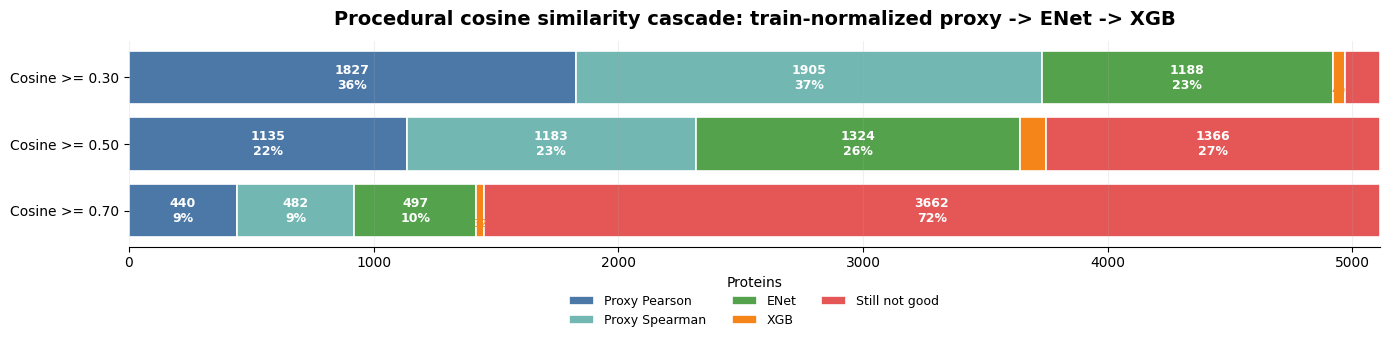

In [12]:
cosine_main_assignments = pd.concat(
    [procedural_cosine_cascade(thr) for thr in COSINE_GOOD_THRESHOLDS],
    ignore_index=True,
)

cosine_main_summary = summarize_assignments(cosine_main_assignments, order=CASCADE_ORDER_BASE)

print("Procedural cosine similarity cascade summary")
display(
    cosine_main_summary
    .pivot_table(index="threshold", columns="stage", values="proteins", fill_value=0, aggfunc="sum")
    .reindex(columns=CASCADE_ORDER_BASE)
)

display(cosine_main_summary)

plot_stacked_partition_rows(
    cosine_main_summary,
    title="Procedural cosine similarity cascade: train-normalized proxy -> ENet -> XGB",
    order=CASCADE_ORDER_BASE,
    save_name="cosine_cascade_030_050_070.png",
    row_label_func=lambda thr: f"Cosine >= {thr:.2f}",
)

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass


## 11. Cosine similarity threshold sweep

A denser threshold sweep gives the same type of sensitivity view as the Pearson threshold sweep.


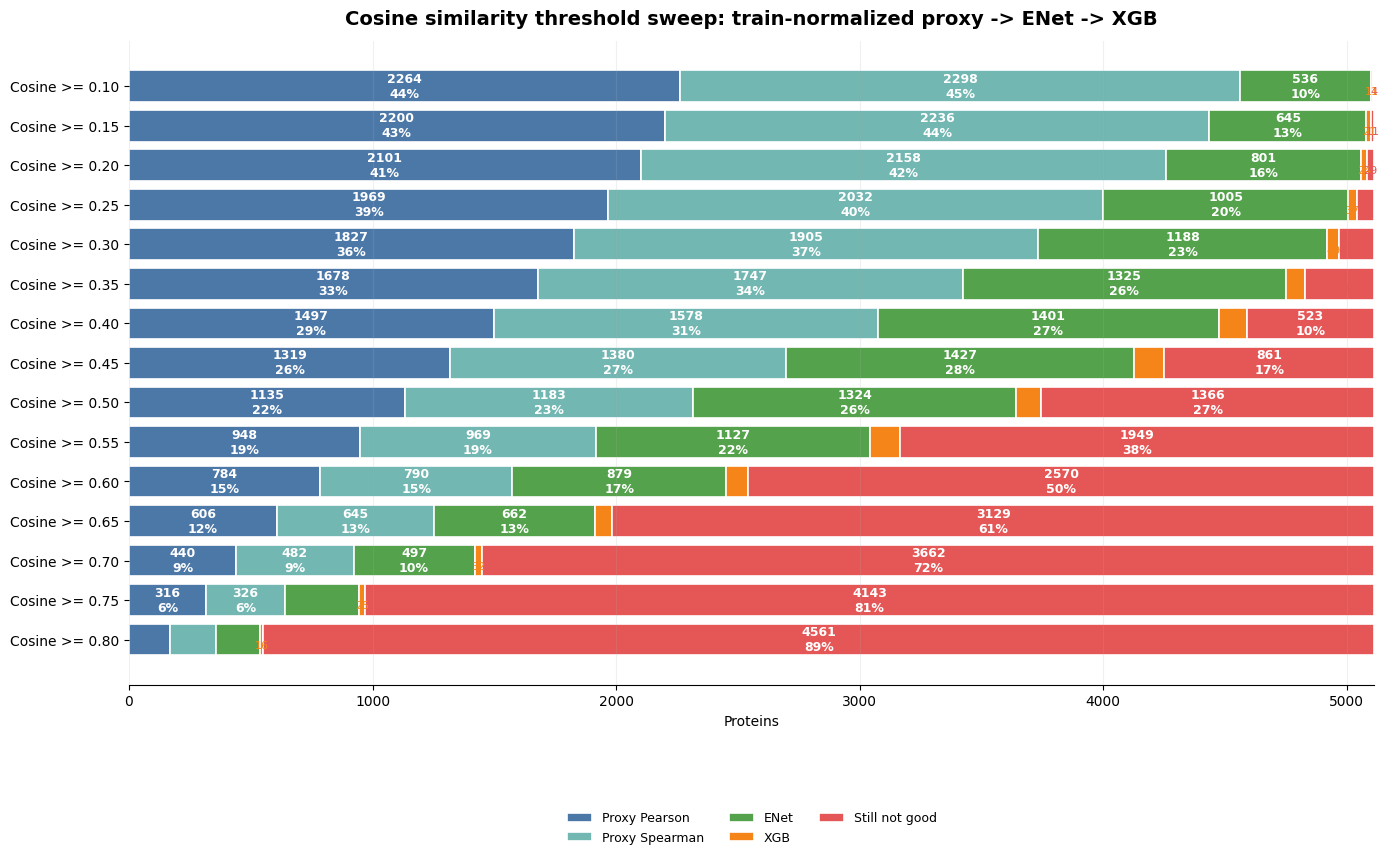

In [13]:
cosine_sweep_assignments = pd.concat(
    [procedural_cosine_cascade(thr) for thr in COSINE_SWEEP_THRESHOLDS],
    ignore_index=True,
)

cosine_sweep_summary = summarize_assignments(cosine_sweep_assignments, order=CASCADE_ORDER_BASE)

plot_stacked_partition_rows(
    cosine_sweep_summary,
    title="Cosine similarity threshold sweep: train-normalized proxy -> ENet -> XGB",
    order=CASCADE_ORDER_BASE,
    save_name="cosine_threshold_sweep.png",
    figsize=(14, max(5, 0.45 * len(COSINE_SWEEP_THRESHOLDS) + 2.0)),
    row_label_func=lambda thr: f"Cosine >= {thr:.2f}",
)

if SAVE_OUTPUTS:
    cosine_sweep_assignments.to_csv(EXPORT_TABLE_DIR / "cosine_threshold_sweep_assignments.csv", index=False)
    cosine_sweep_summary.to_csv(EXPORT_TABLE_DIR / "cosine_threshold_sweep_summary.csv", index=False)

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass


## 12. Proxy-correlation threshold inspection

This asks a different question:

> If we only trust same-gene proxies whose full same-gene correlation is at least some threshold, how many proteins are eligible, and how many are actually predicted well on the held-out test split?

The bar segments are:

- Eligible and good.
- Eligible but not good.
- No eligible proxy.

## 13. Main procedural MSE analyses: 0.30, 0.50, 0.70

This repeats the same procedural cascade for **test MSE**. Lower is better, so a protein is counted as good when `test_mse <= threshold`.

The previous no-threshold MSE winner/improvement plot has been removed; this section keeps the thresholded MSE partitions requested here.


Procedural MSE cascade summary


stage,Proxy Pearson,Proxy Spearman,ENet,XGB,Still not good
threshold,,,,,
0.3,1324,1321,632,54,1782
0.5,2054,2025,469,17,548
0.7,2263,2273,368,6,203


,threshold,stage,proteins,total_proteins,percent
0,0.3,Proxy Pearson,1324,5113,25.894778
1,0.3,Proxy Spearman,1321,5113,25.836104
2,0.3,ENet,632,5113,12.360649
3,0.3,XGB,54,5113,1.056131
4,0.3,Still not good,1782,5113,34.852337
5,0.5,Proxy Pearson,2054,5113,40.172110
6,0.5,Proxy Spearman,2025,5113,39.604929
7,0.5,ENet,469,5113,9.172697
8,0.5,XGB,17,5113,0.332486
9,0.5,Still not good,548,5113,10.717778


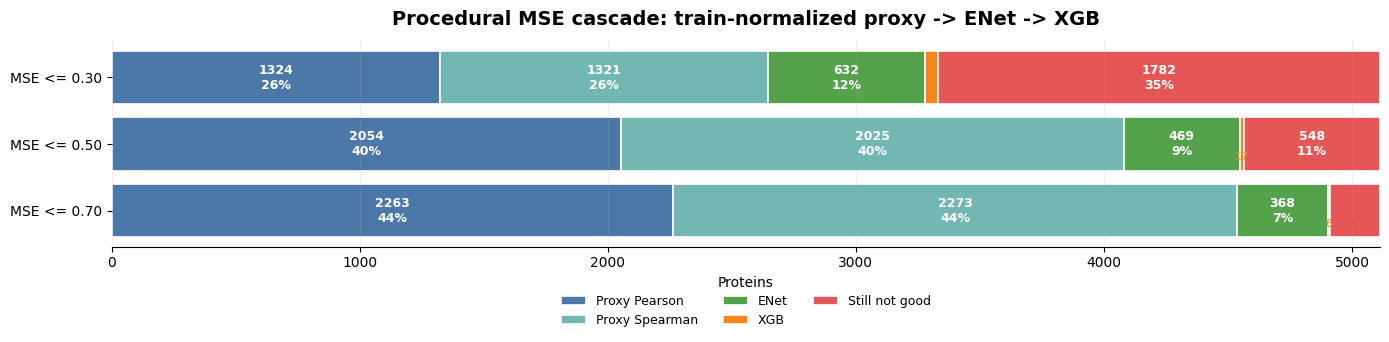

In [14]:
main_mse_assignments = pd.concat(
    [procedural_mse_cascade(thr) for thr in MSE_GOOD_THRESHOLDS],
    ignore_index=True,
)

main_mse_summary = summarize_assignments(main_mse_assignments, order=CASCADE_ORDER_BASE)

print("Procedural MSE cascade summary")
display(
    main_mse_summary
    .pivot_table(index="threshold", columns="stage", values="proteins", fill_value=0, aggfunc="sum")
    .reindex(columns=CASCADE_ORDER_BASE)
)

display(main_mse_summary)

plot_stacked_partition_rows(
    main_mse_summary,
    title="Procedural MSE cascade: train-normalized proxy -> ENet -> XGB",
    order=CASCADE_ORDER_BASE,
    save_name="mse_cascade_030_050_070.png",
    row_label_func=lambda thr: f"MSE <= {thr:.2f}",
)

if SAVE_OUTPUTS:
    main_mse_assignments.to_csv(EXPORT_TABLE_DIR / "mse_cascade_assignments_030_050_070.csv", index=False)
    main_mse_summary.to_csv(EXPORT_TABLE_DIR / "mse_cascade_summary_030_050_070.csv", index=False)

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass


## 14. MSE threshold sweep

This is the granular MSE counterpart of the Pearson and cosine sweeps. Lower MSE is better, so row labels use `MSE <= threshold`.


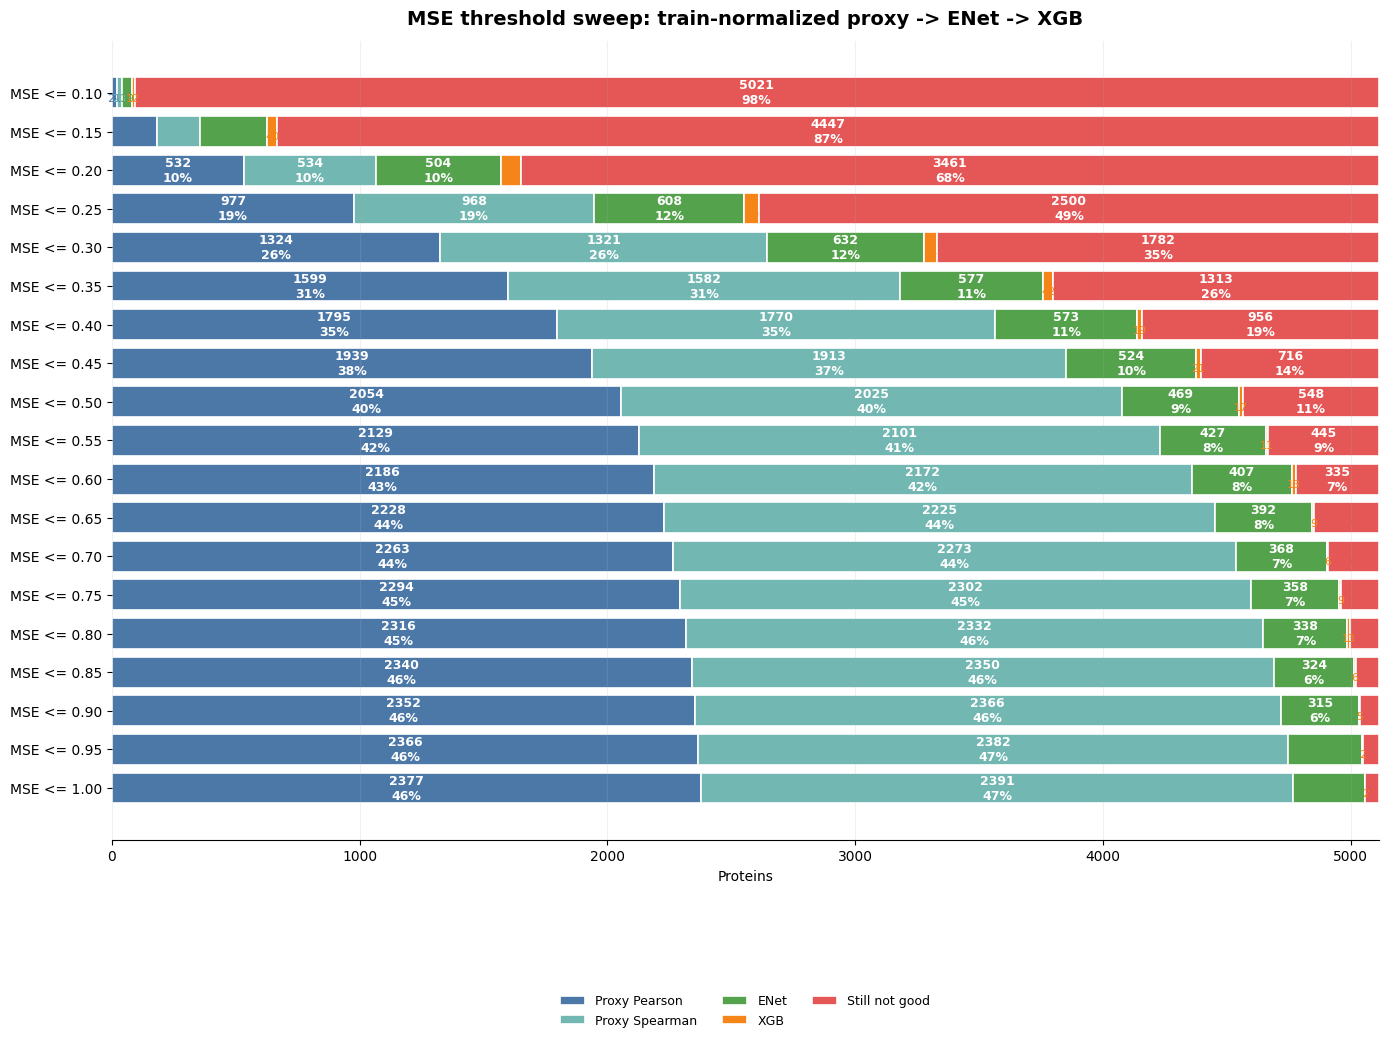

stage,Proxy Pearson,Proxy Spearman,ENet,XGB,Still not good
threshold,,,,,
0.10,21,20,39,12,5021
0.15,181,175,270,40,4447
0.20,532,534,504,82,3461
0.25,977,968,608,60,2500
0.30,1324,1321,632,54,1782
0.35,1599,1582,577,42,1313
0.40,1795,1770,573,19,956
0.45,1939,1913,524,21,716
0.50,2054,2025,469,17,548


In [15]:
# ---------------------------------------------------------------------
# MSE threshold sweep: train-normalized proxy -> ENet -> XGB
# Lower MSE is better, so a protein is "good" when test_mse <= threshold.
# ---------------------------------------------------------------------

mse_sweep_assignments = pd.concat(
    [procedural_mse_cascade(thr) for thr in MSE_SWEEP_THRESHOLDS],
    ignore_index=True,
)

mse_sweep_summary = summarize_assignments(
    mse_sweep_assignments,
    order=CASCADE_ORDER_BASE,
)

plot_stacked_partition_rows(
    mse_sweep_summary,
    title="MSE threshold sweep: train-normalized proxy -> ENet -> XGB",
    order=CASCADE_ORDER_BASE,
    xlabel="Proteins",
    save_name="mse_threshold_sweep.png",
    figsize=(14, max(5, 0.45 * len(MSE_SWEEP_THRESHOLDS) + 2.0)),
    row_label_func=lambda thr: f"MSE <= {thr:.2f}",
)

display(
    mse_sweep_summary
    .pivot_table(
        index="threshold",
        columns="stage",
        values="proteins",
        fill_value=0,
        aggfunc="sum",
    )
    .reindex(columns=CASCADE_ORDER_BASE)
)

if SAVE_OUTPUTS:
    mse_sweep_assignments.to_csv(EXPORT_TABLE_DIR / "mse_threshold_sweep_assignments.csv", index=False)
    mse_sweep_summary.to_csv(EXPORT_TABLE_DIR / "mse_threshold_sweep_summary.csv", index=False)

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass


## 15. Why train-normalized proxy models should improve cosine similarity and MSE

The distribution plot you provided is consistent with the metric behavior in the raw-proxy notebook: transcriptomics values are mostly non-negative and have a large spike near zero, while proteomics values are centered around zero and include negative values.

That mismatch hurts raw proxy predictions because raw RNA values are compared directly against centered protein values. In this proxy-calibrated notebook, the same-gene proxy is instead fitted as a one-feature linear model on training samples only. This gives the proxy an intercept and slope in protein space before evaluating it on held-out samples.


In [16]:
# Diagnostics for distribution, calibration, and proxy-vs-protein metric behavior.
# These values are computed on the matrices actually loaded by this notebook.

def _distribution_diagnostics(name, df):
    values = df.to_numpy(dtype=float)
    finite = np.isfinite(values)
    vals = values[finite]
    return {
        "matrix": name,
        "n_values": int(vals.size),
        "mean": float(np.mean(vals)) if vals.size else np.nan,
        "std": float(np.std(vals)) if vals.size else np.nan,
        "min": float(np.min(vals)) if vals.size else np.nan,
        "median": float(np.median(vals)) if vals.size else np.nan,
        "max": float(np.max(vals)) if vals.size else np.nan,
        "fraction_negative": float(np.mean(vals < 0)) if vals.size else np.nan,
        "fraction_zero_or_near_zero": float(np.mean(np.isclose(vals, 0.0, atol=1e-12))) if vals.size else np.nan,
    }

xy_distribution_diagnostics = pd.DataFrame([
    _distribution_diagnostics("Transcriptomics X", X),
    _distribution_diagnostics("Proteomics Y", Y),
])

display(xy_distribution_diagnostics)

proxy_metric_diagnostics = (
    proxy_results
    .groupby(["proxy_type", "normalization"], dropna=False)
    .agg(
        proteins=("protein", "nunique"),
        median_proxy_corr_full=("same_gene_corr_full", "median"),
        median_test_pearson=("test_pearson_corr", "median"),
        median_test_cosine=("test_cosine_similarity", "median"),
        median_test_mse=("test_mse", "median"),
        mean_test_mse=("test_mse", "mean"),
    )
    .reset_index()
)

display(proxy_metric_diagnostics)


,matrix,n_values,mean,std,min,median,max,fraction_negative,fraction_zero_or_near_zero
0,Transcriptomics X,8344566,2.592417,2.413308,0.000000,2.130931,17.253967,0.000000,0.116077
1,Proteomics Y,1886697,-0.021529,0.786623,-16.951352,-0.023866,7.722932,0.515855,0.000000


,proxy_type,normalization,proteins,median_proxy_corr_full,median_test_pearson,median_test_cosine,median_test_mse,mean_test_mse
0,pearson,train_linear_regression,4843,0.470988,0.482946,0.484671,0.281958,0.346894
1,spearman,train_linear_regression,4843,0.451341,0.482946,0.484671,0.281958,0.346894


**Interpretation.** Pearson correlation and Spearman correlation mainly measure whether two vectors co-vary across samples. They do not require the two vectors to have the same offset or scale. Spearman is even more forgiving because it only uses ranks.

MSE and cosine similarity ask different questions. MSE compares values directly, so raw non-negative RNA values can have large error when the protein vector is centered around zero or includes negative values. Cosine similarity compares the angle between the raw prediction vector and the protein vector; it is sensitive to centering and sign patterns.

The train-normalized proxy fixes the simplest version of that mismatch by learning:

```text
protein = intercept + slope * RNA
```

on training samples only. This should improve MSE and often cosine similarity because predictions are now on the protein scale. It should not meaningfully change Pearson/Spearman association in cases where the learned slope is positive, because correlation is almost invariant to linear rescaling and intercept shifts. If the learned slope is negative, Pearson can flip sign, which is biologically possible if the train relationship is negative.

This calibration is not leakage because the fitted intercept and slope use only `X_train` and `Y_train`. The test protein values are used only for final metric evaluation.


## 16. Load scTranslator predictions from `.npz` bundles

This section expects the files to be in the same folder as the notebook:

```text
sc_predictions_2M.npz
sc_predictions_160K.npz
sc_predictions_10K.npz
```

The bundle format is assumed to contain:

```text
predictions
protein_names
cell_names
```

Predictions are reindexed to match `GT_scaled.index` and `GT_scaled.columns`, then evaluated on the exact ENet/XGB H5 test split.

In [17]:
sctranslator_pred_dfs = load_sctranslator_prediction_tables()
sctranslator_results = evaluate_sctranslator_predictions(
    sctranslator_pred_dfs,
    gt=GT_scaled,
    eval_samples=test_samples,
)

sctranslator_results = add_family_group(sctranslator_results)

print("scTranslator result rows:", len(sctranslator_results))
if len(sctranslator_results):
    display(
        sctranslator_results.groupby("run_label")
        .agg(
            proteins=("protein", "nunique"),
            pearson_median=("test_pearson_corr", "median"),
            pearson_mean=("test_pearson_corr", "mean"),
            mse_median=("test_mse", "median"),
        )
        .sort_values("pearson_median", ascending=False)
    )
    display(sctranslator_results.head())
else:
    print("No scTranslator predictions were loaded. The final rescue plots below will be skipped.")

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

scTranslator result rows: 15339


,proteins,pearson_median,pearson_mean,mse_median
run_label,,,,
scTranslator 160K,5113,-0.004724,-0.007454,13198.581632
scTranslator 2M,5113,-0.005029,-0.003427,11707.122961
scTranslator 10K,5113,-0.012217,-0.011571,0.674487


,protein,run_label,model_family,family_group,sc_size,source_folder,test_mse,test_pearson_corr,test_cosine_similarity,n_test_used,train_n,test_n,split_hash,h5_path
0,A2M,scTranslator 2M,sctranslator,sctranslator,2M,scTranslator npz,1929.069576,-0.188503,0.354583,74,NaN,74,d0750f1c44a2,
1,AAAS,scTranslator 2M,sctranslator,sctranslator,2M,scTranslator npz,2553.709484,-0.005944,-0.149269,74,NaN,74,d0750f1c44a2,
2,AACS,scTranslator 2M,sctranslator,sctranslator,2M,scTranslator npz,47197.703064,0.012968,0.062528,74,NaN,74,d0750f1c44a2,
3,AAGAB,scTranslator 2M,sctranslator,sctranslator,2M,scTranslator npz,616.272881,0.181502,0.032709,74,NaN,74,d0750f1c44a2,
4,AAK1,scTranslator 2M,sctranslator,sctranslator,2M,scTranslator npz,87522.725488,0.310178,-0.129605,74,NaN,74,d0750f1c44a2,


## 17. Final question: among proteins not predicted well by proxy, ENet, or XGB, does scTranslator perform well?

For each Pearson threshold, this section first runs the base cascade:

```text
Proxy → ENet → XGB
```

Then it takes only the proteins still not predicted well and asks whether the best scTranslator prediction reaches the same Pearson threshold.

Full procedural cascade with scTranslator as final rescue


stage,Proxy Pearson,Proxy Spearman,ENet,XGB,scTranslator 2M,scTranslator 160K,scTranslator 10K,Still not good after scTranslator
threshold,,,,,,,,
0.3,1815,1837,1238,49,1,1,0,172
0.5,1147,1140,1265,116,0,0,0,1445
0.7,448,472,486,37,0,0,0,3670


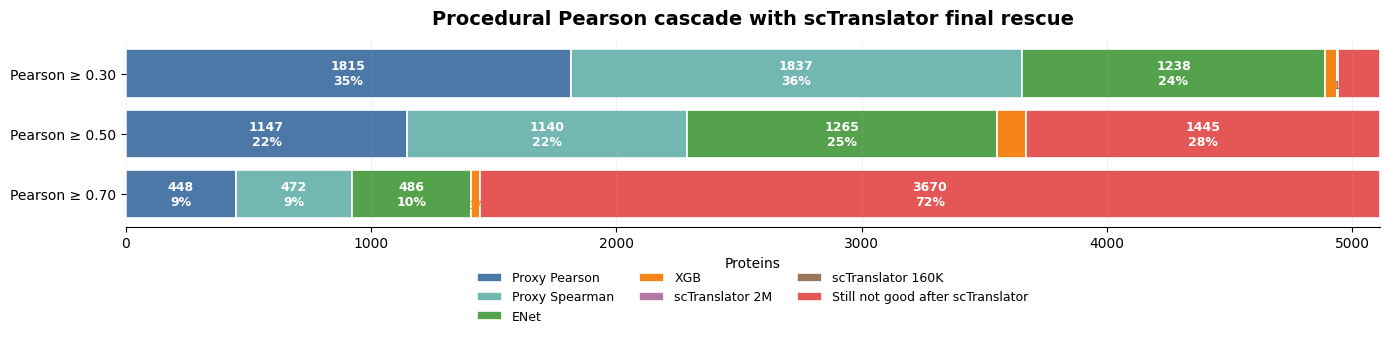

Focused scTranslator rescue among proxy/ENet/XGB failures


stage,scTranslator 2M,scTranslator 160K,scTranslator 10K,Still not good after scTranslator
threshold,,,,
0.3,1,1,0,172
0.5,0,0,0,1445
0.7,0,0,0,3670


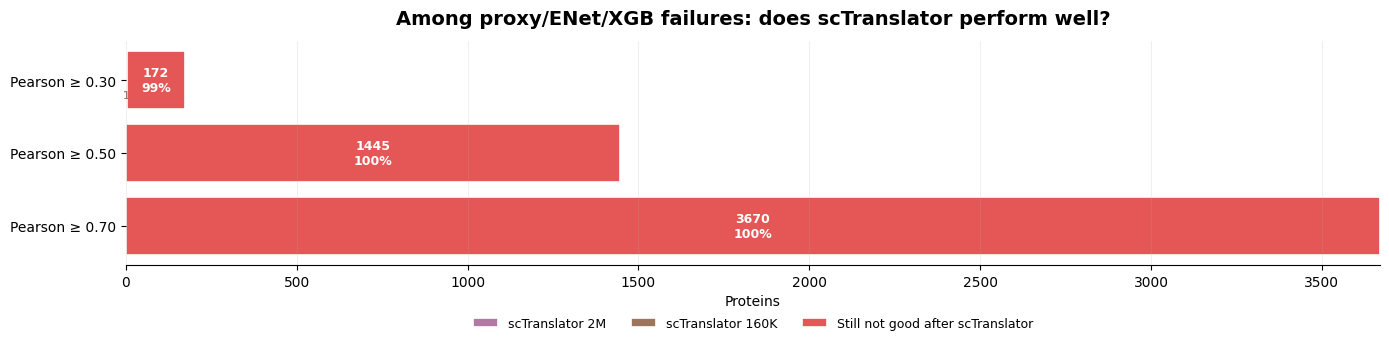

In [18]:
if len(sctranslator_results) > 0:
    sctranslator_best_pearson = best_per_protein(sctranslator_results, "test_pearson_corr", higher=True)

    sc_assignments = pd.concat(
        [
            procedural_pearson_cascade(
                thr,
                include_sc=True,
                sctranslator_best=sctranslator_best_pearson,
            )
            for thr in PEARSON_GOOD_THRESHOLDS
        ],
        ignore_index=True,
    )

    sc_summary = summarize_assignments(sc_assignments, order=CASCADE_ORDER_WITH_SC)

    print("Full procedural cascade with scTranslator as final rescue")
    display(
        sc_summary
        .pivot_table(index="threshold", columns="stage", values="proteins", fill_value=0, aggfunc="sum")
        .reindex(columns=CASCADE_ORDER_WITH_SC)
    )

    plot_stacked_partition_rows(
        sc_summary,
        title="Procedural Pearson cascade with scTranslator final rescue",
        order=CASCADE_ORDER_WITH_SC,
        save_name="pearson_cascade_with_sctranslator.png",
    )

    # Focused answer: among base failures only, how many are rescued by scTranslator?
    focused_rows = []
    for thr in PEARSON_GOOD_THRESHOLDS:
        base = procedural_pearson_cascade(thr, include_sc=False)
        base_failures = set(base.loc[base["stage"].eq("Still not good"), "protein"].astype(str))

        sc_best_idx = _index_by_protein(sctranslator_best_pearson)
        for protein in sorted(base_failures):
            if protein in sc_best_idx.index:
                row = sc_best_idx.loc[protein]
                value = row.get("test_pearson_corr", np.nan)
                if np.isfinite(value) and value >= thr:
                    stage = f"scTranslator {row.get('sc_size', row.get('run_label', '')).replace('scTranslator ', '')}"
                else:
                    stage = "Still not good after scTranslator"
            else:
                value = np.nan
                stage = "Still not good after scTranslator"

            focused_rows.append({
                "protein": protein,
                "threshold": thr,
                "stage": stage,
                "test_pearson_corr": value,
            })

    sc_rescue_only = pd.DataFrame(focused_rows)
    sc_rescue_summary = summarize_assignments(
        sc_rescue_only,
        order=["scTranslator 2M", "scTranslator 160K", "scTranslator 10K", "Still not good after scTranslator"],
    )

    print("Focused scTranslator rescue among proxy/ENet/XGB failures")
    display(
        sc_rescue_summary
        .pivot_table(index="threshold", columns="stage", values="proteins", fill_value=0, aggfunc="sum")
        .reindex(columns=["scTranslator 2M", "scTranslator 160K", "scTranslator 10K", "Still not good after scTranslator"])
    )

    plot_stacked_partition_rows(
        sc_rescue_summary,
        title="Among proxy/ENet/XGB failures: does scTranslator perform well?",
        order=["scTranslator 2M", "scTranslator 160K", "scTranslator 10K", "Still not good after scTranslator"],
        save_name="sctranslator_rescue_after_failures.png",
    )

    if SAVE_OUTPUTS:
        sctranslator_results.to_csv(EXPORT_TABLE_DIR / "sctranslator_metrics.csv", index=False)
        sc_assignments.to_csv(EXPORT_TABLE_DIR / "pearson_cascade_with_sctranslator_assignments.csv", index=False)
        sc_rescue_only.to_csv(EXPORT_TABLE_DIR / "sctranslator_rescue_only_assignments.csv", index=False)
        sc_summary.to_csv(EXPORT_TABLE_DIR / "pearson_cascade_with_sctranslator_summary.csv", index=False)
        sc_rescue_summary.to_csv(EXPORT_TABLE_DIR / "sctranslator_rescue_only_summary.csv", index=False)
else:
    print("Skipped: no scTranslator predictions were loaded.")

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

## 18. Optional: export final base tables

Set `SAVE_OUTPUTS = True` in the setup cell to save tables and figures automatically.

In [19]:
if SAVE_OUTPUTS:
    all_results.to_csv(EXPORT_TABLE_DIR / "all_results_proxy_enet_xgb.csv", index=False)
    proxy_results.to_csv(EXPORT_TABLE_DIR / "proxy_results_all_same_gene.csv", index=False)

    main_assignments.to_csv(EXPORT_TABLE_DIR / "pearson_cascade_assignments_030_050_070.csv", index=False)
    main_summary.to_csv(EXPORT_TABLE_DIR / "pearson_cascade_summary_030_050_070.csv", index=False)
    sweep_assignments.to_csv(EXPORT_TABLE_DIR / "pearson_threshold_sweep_assignments.csv", index=False)
    sweep_summary.to_csv(EXPORT_TABLE_DIR / "pearson_threshold_sweep_summary.csv", index=False)

    cosine_main_assignments.to_csv(EXPORT_TABLE_DIR / "cosine_cascade_assignments_030_050_070.csv", index=False)
    cosine_main_summary.to_csv(EXPORT_TABLE_DIR / "cosine_cascade_summary_030_050_070.csv", index=False)
    cosine_sweep_assignments.to_csv(EXPORT_TABLE_DIR / "cosine_threshold_sweep_assignments.csv", index=False)
    cosine_sweep_summary.to_csv(EXPORT_TABLE_DIR / "cosine_threshold_sweep_summary.csv", index=False)

    main_mse_assignments.to_csv(EXPORT_TABLE_DIR / "mse_cascade_assignments_030_050_070.csv", index=False)
    main_mse_summary.to_csv(EXPORT_TABLE_DIR / "mse_cascade_summary_030_050_070.csv", index=False)
    mse_sweep_assignments.to_csv(EXPORT_TABLE_DIR / "mse_threshold_sweep_assignments.csv", index=False)
    mse_sweep_summary.to_csv(EXPORT_TABLE_DIR / "mse_threshold_sweep_summary.csv", index=False)

    print("Saved outputs to:")
    print("-", EXPORT_TABLE_DIR)
    print("-", FIGURE_DIR)
else:
    print("SAVE_OUTPUTS is False. Change it to True in the setup cell to export CSVs and figures.")

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass


SAVE_OUTPUTS is False. Change it to True in the setup cell to export CSVs and figures.


In [20]:
# =====================================================================
# Export protein names by cascade/partition threshold and model/stage
#
# Works in:
#   - procedural_ccle.ipynb
#   - 9.procedural_cptac.ipynb
#
# What it saves:
#   1. cascade_partition_proteins_long.csv
#      one protein per row
#
#   2. cascade_partition_proteins_grouped.csv
#      one row per dataset / analysis / threshold / stage,
#      with all protein names joined into one field
#
#   3. cascade_partition_proteins_files_manifest.csv
#      index of all separate files
#
#   4. protein_lists_one_file_per_partition/
#      one separate CSV for each threshold + cascade stage/model
# =====================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import re
import hashlib

SAVE_CASCADE_PROTEIN_EXPORTS = True

# ---------------------------------------------------------------------
# Output folders
# ---------------------------------------------------------------------

try:
    EXPORT_TABLE_DIR
except NameError:
    EXPORT_TABLE_DIR = Path("procedural_proxy_norm_tables")

EXPORT_TABLE_DIR = Path(EXPORT_TABLE_DIR)
EXPORT_TABLE_DIR.mkdir(parents=True, exist_ok=True)

PROTEIN_EXPORT_DIR = EXPORT_TABLE_DIR / "protein_names_by_cascade_partition"
PROTEIN_EXPORT_DIR.mkdir(parents=True, exist_ok=True)

SPLIT_EXPORT_DIR = PROTEIN_EXPORT_DIR / "protein_lists_one_file_per_partition"
SPLIT_EXPORT_DIR.mkdir(parents=True, exist_ok=True)


# ---------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------


# ---------------------------------------------------------------------
# Detect notebook type and collect available assignment tables
# ---------------------------------------------------------------------

is_cptac = (
    _valid_df(_get_global("main_pearson_assignments"))
    or _valid_df(_get_global("pearson_sweep_assignments"))
    or _valid_df(_get_global("mse_percentile_assignments"))
    or _valid_df(_get_global("final_sc_assignments"))
)

if is_cptac:
    default_dataset = "CPTAC"

    candidate_tables = [
        ("main_pearson_cascade", "main_pearson_assignments", _get_global("main_pearson_assignments")),
        ("pearson_threshold_sweep", "pearson_sweep_assignments", _get_global("pearson_sweep_assignments")),
        ("proxy_correlation_threshold_sweep", "proxy_corr_assignments", _get_global("proxy_corr_assignments")),
        ("mse_threshold_sweep", "mse_sweep_assignments", _get_global("mse_sweep_assignments")),
        ("mse_percentile_threshold_sweep", "mse_percentile_assignments", _get_global("mse_percentile_assignments")),
        ("mse_winner_partition", "mse_winner", _get_global("mse_winner")),
        ("mse_procedural_improvement_partition", "mse_improvement", _get_global("mse_improvement")),
        ("cosine_threshold_sweep", "cosine_sweep_assignments", _get_global("cosine_sweep_assignments")),
        ("pearson_cascade_with_sctranslator", "final_sc_assignments", _get_global("final_sc_assignments")),
    ]

else:
    default_dataset = "CCLE"

    candidate_tables = [
        ("main_pearson_cascade", "main_assignments", _get_global("main_assignments")),
        ("pearson_threshold_sweep", "sweep_assignments", _get_global("sweep_assignments")),
        ("main_cosine_cascade", "cosine_main_assignments", _get_global("cosine_main_assignments")),
        ("cosine_threshold_sweep", "cosine_sweep_assignments", _get_global("cosine_sweep_assignments")),
        ("proxy_correlation_threshold_sweep", "proxy_corr_assignments", _get_global("proxy_corr_assignments")),
        ("main_mse_cascade", "main_mse_assignments", _get_global("main_mse_assignments")),
        ("mse_threshold_sweep", "mse_sweep_assignments", _get_global("mse_sweep_assignments")),
        ("pearson_cascade_with_sctranslator", "sc_assignments", _get_global("sc_assignments")),
        ("sctranslator_rescue_only", "sc_rescue_only", _get_global("sc_rescue_only")),
    ]


standardized_tables = []

for analysis_name, source_variable, df in candidate_tables:
    if not _valid_df(df):
        print(f"Skipped missing or empty table: {source_variable}")
        continue

    tmp = _standardize_assignment_table(
        df=df,
        analysis_name=analysis_name,
        source_variable=source_variable,
        default_dataset=default_dataset,
    )

    if _valid_df(tmp):
        standardized_tables.append(tmp)
        print(
            f"Included: {source_variable} -> {analysis_name} "
            f"({len(tmp):,} protein rows)"
        )

if len(standardized_tables) == 0:
    raise ValueError(
        "No assignment tables were found. "
        "Run the cascade/sweep plotting cells first, then rerun this export cell."
    )


# ---------------------------------------------------------------------
# Long protein-level table
# ---------------------------------------------------------------------

cascade_partition_proteins_long = pd.concat(
    standardized_tables,
    ignore_index=True,
)

cascade_partition_proteins_long = (
    cascade_partition_proteins_long
    .sort_values(
        [
            "dataset",
            "analysis",
            "threshold_label",
            "stage",
            "protein",
        ]
    )
    .reset_index(drop=True)
)


# ---------------------------------------------------------------------
# Grouped readable table: one row per graph segment
# ---------------------------------------------------------------------

group_cols = [
    "dataset",
    "analysis",
    "source_variable",
    "threshold_label",
    "stage",
]

cascade_partition_proteins_grouped = (
    cascade_partition_proteins_long
    .groupby(group_cols, dropna=False)
    .agg(
        n_proteins=("protein", "nunique"),
        protein_names=("protein", lambda x: "; ".join(sorted(set(map(str, x))))),
    )
    .reset_index()
    .sort_values(group_cols)
    .reset_index(drop=True)
)

cascade_partition_proteins_grouped["protein_names_preview"] = (
    cascade_partition_proteins_grouped["protein_names"]
    .str.split("; ")
    .apply(lambda xs: "; ".join(xs[:25]) + ("; ..." if len(xs) > 25 else ""))
)


# ---------------------------------------------------------------------
# One file per dataset / analysis / threshold / stage
# ---------------------------------------------------------------------

manifest_rows = []
split_tables = []

for keys, sub in cascade_partition_proteins_long.groupby(group_cols, dropna=False):
    info = dict(zip(group_cols, keys))

    file_stem = "__".join(
        [
            _safe_name(info["dataset"]),
            _safe_name(info["analysis"]),
            _safe_name(info["threshold_label"]),
            _safe_name(info["stage"]),
        ]
    )

    file_name = f"{file_stem}.csv"
    out_path = SPLIT_EXPORT_DIR / file_name

    keep_cols = [
        c for c in [
            "dataset",
            "analysis",
            "source_variable",
            "threshold_label",
            "stage",
            "protein",
            "threshold",
            "prediction_threshold",
            "corr_threshold",
            "mse_percentile_threshold",
            "metric",
            "test_pearson_corr",
            "test_mse",
            "test_cosine_similarity",
            "best_mse",
            "proxy_mse",
            "enet_mse",
            "xgb_mse",
            "same_gene_corr_full",
            "proxy_corr",
            "run_label",
            "model_name",
            "proxy_type",
        ]
        if c in sub.columns
    ]

    split_df = (
        sub[keep_cols]
        .drop_duplicates()
        .sort_values("protein")
        .reset_index(drop=True)
    )

    split_tables.append((out_path, split_df))

    manifest_rows.append(
        {
            "dataset": info["dataset"],
            "analysis": info["analysis"],
            "source_variable": info["source_variable"],
            "threshold_label": info["threshold_label"],
            "stage": info["stage"],
            "n_proteins": split_df["protein"].nunique(),
            "file_name": file_name,
            "relative_path": str(out_path.relative_to(PROTEIN_EXPORT_DIR)),
        }
    )

cascade_partition_proteins_manifest = (
    pd.DataFrame(manifest_rows)
    .sort_values(
        [
            "dataset",
            "analysis",
            "threshold_label",
            "stage",
        ]
    )
    .reset_index(drop=True)
)


# ---------------------------------------------------------------------
# Display BEFORE saving
# ---------------------------------------------------------------------

print("\nGrouped table to be saved:")
display(
    cascade_partition_proteins_grouped[
        [
            "dataset",
            "analysis",
            "source_variable",
            "threshold_label",
            "stage",
            "n_proteins",
            "protein_names_preview",
        ]
    ]
)

print("\nLong protein-level table to be saved, first 100 rows:")
display(cascade_partition_proteins_long.head(100))

print("\nManifest of one-file-per-partition exports to be saved:")
display(cascade_partition_proteins_manifest)


# ---------------------------------------------------------------------
# Save
# ---------------------------------------------------------------------

if SAVE_CASCADE_PROTEIN_EXPORTS:
    long_path = PROTEIN_EXPORT_DIR / "cascade_partition_proteins_long.csv"
    grouped_path = PROTEIN_EXPORT_DIR / "cascade_partition_proteins_grouped.csv"
    manifest_path = PROTEIN_EXPORT_DIR / "cascade_partition_proteins_files_manifest.csv"

    cascade_partition_proteins_long.to_csv(long_path, index=False)
    cascade_partition_proteins_grouped.to_csv(grouped_path, index=False)
    cascade_partition_proteins_manifest.to_csv(manifest_path, index=False)

    for out_path, split_df in split_tables:
        split_df.to_csv(out_path, index=False)

    print("\nSaved protein partition exports:")
    print("Long protein-level table:", long_path)
    print("Grouped protein-name table:", grouped_path)
    print("Manifest:", manifest_path)
    print("One file per threshold/stage:", SPLIT_EXPORT_DIR)
else:
    print("SAVE_CASCADE_PROTEIN_EXPORTS is False, so nothing was saved.")

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

Included: main_assignments -> main_pearson_cascade (15,339 protein rows)
Included: sweep_assignments -> pearson_threshold_sweep (76,695 protein rows)
Included: cosine_main_assignments -> main_cosine_cascade (15,339 protein rows)
Included: cosine_sweep_assignments -> cosine_threshold_sweep (76,695 protein rows)
Skipped missing or empty table: proxy_corr_assignments
Included: main_mse_assignments -> main_mse_cascade (15,339 protein rows)
Included: mse_sweep_assignments -> mse_threshold_sweep (97,147 protein rows)
Included: sc_assignments -> pearson_cascade_with_sctranslator (15,339 protein rows)
Included: sc_rescue_only -> sctranslator_rescue_only (5,289 protein rows)

Grouped table to be saved:


,dataset,analysis,source_variable,threshold_label,stage,n_proteins,protein_names_preview
0,CCLE,cosine_threshold_sweep,cosine_sweep_assignments,Cosine >= 0.10,ENet,536,AARS; AATF; ACTA2; ADCK3; ADCK4; ADPRHL2; ADRB...
1,CCLE,cosine_threshold_sweep,cosine_sweep_assignments,Cosine >= 0.10,Proxy Pearson,2264,A2M; AACS; AAGAB; AAMDC; AAR2; AARSD1; AASS; A...
2,CCLE,cosine_threshold_sweep,cosine_sweep_assignments,Cosine >= 0.10,Proxy Spearman,2298,AAAS; AAK1; AAMP; AARS2; AASDHPPT; ABCB6; ABCB...
3,CCLE,cosine_threshold_sweep,cosine_sweep_assignments,Cosine >= 0.10,Still not good,4,C14orf166; PPP1CC; RPL14; RPLP0
4,CCLE,cosine_threshold_sweep,cosine_sweep_assignments,Cosine >= 0.10,XGB,11,ATP5SL; CEP290; CLEC16A; EIF3K; HIST1H1C; HIST...
...,...,...,...,...,...,...,...
307,CCLE,sctranslator_rescue_only,sc_rescue_only,Pearson >= 0.30,Still not good after scTranslator,172,ABT1; ANAPC1; ANAPC10; ANAPC2; ATP5E; ATP5SL; ...
308,CCLE,sctranslator_rescue_only,sc_rescue_only,Pearson >= 0.30,scTranslator 160K,1,RPS20
309,CCLE,sctranslator_rescue_only,sc_rescue_only,Pearson >= 0.30,scTranslator 2M,1,PPP2R1A
310,CCLE,sctranslator_rescue_only,sc_rescue_only,Pearson >= 0.50,Still not good after scTranslator,1445,AAGAB; AAMP; AAR2; AARS2; ABCE1; ABCF2; ABT1; ...



Long protein-level table to be saved, first 100 rows:


,analysis,source_variable,dataset,threshold_label,stage,protein,threshold,metric,test_pearson_corr,run_label,test_mse
0,cosine_threshold_sweep,cosine_sweep_assignments,CCLE,Cosine >= 0.10,ENet,AARS,0.1,0.515504,NaN,enet | ranking | fast | k2000,NaN
1,cosine_threshold_sweep,cosine_sweep_assignments,CCLE,Cosine >= 0.10,ENet,AATF,0.1,0.530707,NaN,enet_zbig | zscore | fast | k5000,NaN
2,cosine_threshold_sweep,cosine_sweep_assignments,CCLE,Cosine >= 0.10,ENet,ACTA2,0.1,0.680171,NaN,enet_zbig | zscore | fast | k5000,NaN
3,cosine_threshold_sweep,cosine_sweep_assignments,CCLE,Cosine >= 0.10,ENet,ADCK3,0.1,0.705231,NaN,enet | none | fast | k2000,NaN
4,cosine_threshold_sweep,cosine_sweep_assignments,CCLE,Cosine >= 0.10,ENet,ADCK4,0.1,0.734781,NaN,enet_zbig | zscore | fast | k5000,NaN
...,...,...,...,...,...,...,...,...,...,...,...
95,cosine_threshold_sweep,cosine_sweep_assignments,CCLE,Cosine >= 0.10,ENet,COL4A3BP,0.1,0.631024,NaN,enet | none | fast | k2000,NaN
96,cosine_threshold_sweep,cosine_sweep_assignments,CCLE,Cosine >= 0.10,ENet,COPS3,0.1,0.251341,NaN,enet_zbig | zscore | fast | k5000,NaN
97,cosine_threshold_sweep,cosine_sweep_assignments,CCLE,Cosine >= 0.10,ENet,COPS8,0.1,0.497650,NaN,enet_zbig | zscore | fast | k5000,NaN
98,cosine_threshold_sweep,cosine_sweep_assignments,CCLE,Cosine >= 0.10,ENet,COX7A2L,0.1,0.386170,NaN,enet | zscore | fast | k2000,NaN



Manifest of one-file-per-partition exports to be saved:


,dataset,analysis,source_variable,threshold_label,stage,n_proteins,file_name,relative_path
0,CCLE,cosine_threshold_sweep,cosine_sweep_assignments,Cosine >= 0.10,ENet,536,CCLE__cosine_threshold_sweep__Cosine_gteq_0p10...,protein_lists_one_file_per_partition\CCLE__cos...
1,CCLE,cosine_threshold_sweep,cosine_sweep_assignments,Cosine >= 0.10,Proxy Pearson,2264,CCLE__cosine_threshold_sweep__Cosine_gteq_0p10...,protein_lists_one_file_per_partition\CCLE__cos...
2,CCLE,cosine_threshold_sweep,cosine_sweep_assignments,Cosine >= 0.10,Proxy Spearman,2298,CCLE__cosine_threshold_sweep__Cosine_gteq_0p10...,protein_lists_one_file_per_partition\CCLE__cos...
3,CCLE,cosine_threshold_sweep,cosine_sweep_assignments,Cosine >= 0.10,Still not good,4,CCLE__cosine_threshold_sweep__Cosine_gteq_0p10...,protein_lists_one_file_per_partition\CCLE__cos...
4,CCLE,cosine_threshold_sweep,cosine_sweep_assignments,Cosine >= 0.10,XGB,11,CCLE__cosine_threshold_sweep__Cosine_gteq_0p10...,protein_lists_one_file_per_partition\CCLE__cos...
...,...,...,...,...,...,...,...,...
307,CCLE,sctranslator_rescue_only,sc_rescue_only,Pearson >= 0.30,Still not good after scTranslator,172,CCLE__sctranslator_rescue_only__Pearson_gteq_0...,protein_lists_one_file_per_partition\CCLE__sct...
308,CCLE,sctranslator_rescue_only,sc_rescue_only,Pearson >= 0.30,scTranslator 160K,1,CCLE__sctranslator_rescue_only__Pearson_gteq_0...,protein_lists_one_file_per_partition\CCLE__sct...
309,CCLE,sctranslator_rescue_only,sc_rescue_only,Pearson >= 0.30,scTranslator 2M,1,CCLE__sctranslator_rescue_only__Pearson_gteq_0...,protein_lists_one_file_per_partition\CCLE__sct...
310,CCLE,sctranslator_rescue_only,sc_rescue_only,Pearson >= 0.50,Still not good after scTranslator,1445,CCLE__sctranslator_rescue_only__Pearson_gteq_0...,protein_lists_one_file_per_partition\CCLE__sct...



Saved protein partition exports:
Long protein-level table: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\procedural_proxy_norm_tables\protein_names_by_cascade_partition\cascade_partition_proteins_long.csv
Grouped protein-name table: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\procedural_proxy_norm_tables\protein_names_by_cascade_partition\cascade_partition_proteins_grouped.csv
Manifest: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\procedural_proxy_norm_tables\protein_names_by_cascade_partition\cascade_partition_proteins_files_manifest.csv
One file per threshold/stage: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\procedural_proxy_norm_tables\protein_names_by_cascade_partition\protein_lists_one_file_per_partition
